**Portfolio Deliverable 1 Figure Generation**

**Lung Adenocarcinoma (LUAD) Multi-Omics Target Discovery Package**

This notebook regenerates the figures used in Portfolio Deliverable 1. 

**Data sources:** `data/luad_transcriptomics.tsv`, `data/luad_proteomics.tsv`, `data/luad_gwas.tsv` (generated in Module 2 from the CPTAC LUAD cohort and the NHGRI-EBI GWAS Catalog).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

rna_de = pd.read_csv('../../data/luad_transcriptomics.tsv', sep='\t')
protein_de = pd.read_csv('../../data/luad_proteomics.tsv', sep='\t')
gwas_gene_level = pd.read_csv('../../data/luad_gwas.tsv', sep='\t')

print("RNA:", rna_de.shape, "Protein:", protein_de.shape, "GWAS:", gwas_gene_level.shape)

RNA: (59286, 3) Protein: (12900, 3) GWAS: (361, 2)


154 genes, 112 concordant


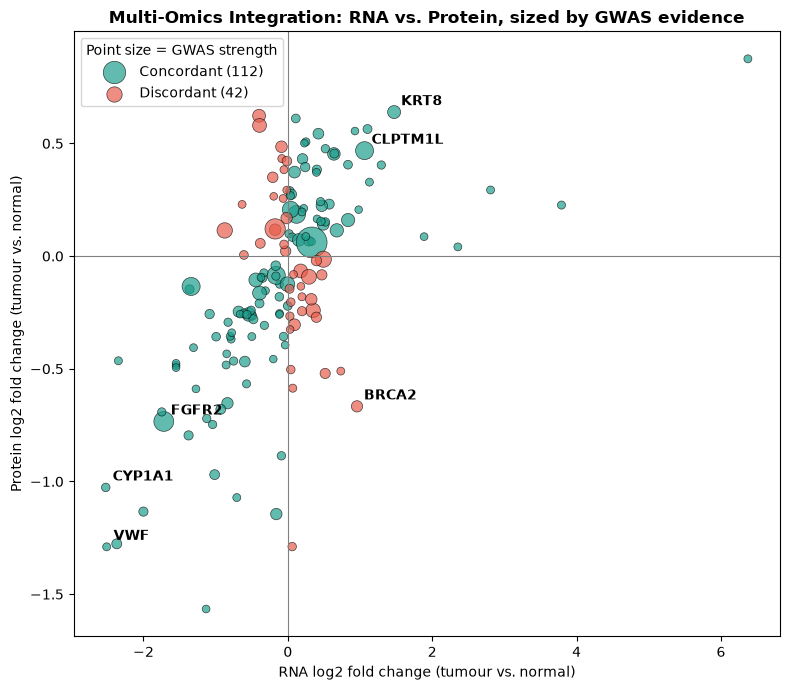

In [2]:
import matplotlib.pyplot as plt

rna = rna_de.rename(columns={rna_de.columns[1]: "rna_lfc"})[["gene", "rna_lfc"]]
prot = protein_de.rename(columns={protein_de.columns[1]: "prot_lfc"})[["gene", "prot_lfc"]]
gw = gwas_gene_level.rename(columns={gwas_gene_level.columns[1]: "gwas"})[["gene", "gwas"]]

m = rna.merge(prot, on="gene").merge(gw, on="gene")
m["concordant"] = (m.rna_lfc * m.prot_lfc) > 0
print(len(m), "genes,", m.concordant.sum(), "concordant")

fig, ax = plt.subplots(figsize=(8, 7))
for conc, color, lab in [(True, "#1E9E8C", "Concordant"), (False, "#E85D4D", "Discordant")]:
    d = m[m.concordant == conc]
    ax.scatter(d.rna_lfc, d.prot_lfc, s=d.gwas * 6, c=color, alpha=0.7,
               edgecolor="black", linewidth=0.5, label=f"{lab} ({len(d)})")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
for g in ["FGFR2", "CLPTM1L", "CYP1A1", "BRCA2", "KRT8", "VWF"]:
    r = m[m.gene == g]
    if len(r):
        ax.annotate(g, (r.rna_lfc.iloc[0], r.prot_lfc.iloc[0]), xytext=(5, 5),
                    textcoords="offset points", fontsize=10, fontweight="bold")
ax.set_xlabel("RNA log2 fold change (tumour vs. normal)")
ax.set_ylabel("Protein log2 fold change (tumour vs. normal)")
ax.set_title("Multi-Omics Integration: RNA vs. Protein, sized by GWAS evidence", fontweight="bold")
ax.legend(title="Point size = GWAS strength")
plt.tight_layout()
plt.savefig("luad_integration_scatter.png", dpi=220)
plt.show()

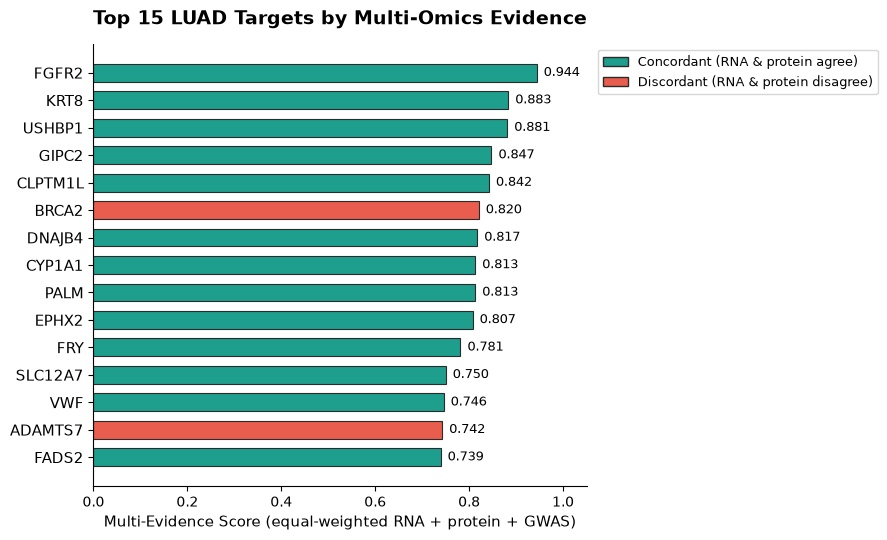

In [3]:
targets = pd.read_csv('../module2/targets_luad.csv')
top15 = targets.head(15)

colors = ["#1E9E8C" if c else "#E85D4D" for c in top15["concordant"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = range(len(top15))[::-1]
bars = ax.barh(y_pos, top15["score"], color=colors,
               edgecolor="#2B2B2B", linewidth=0.8, height=0.65)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(top15["gene"], fontsize=11)
ax.set_xlabel("Multi-Evidence Score (equal-weighted RNA + protein + GWAS)", fontsize=10.5)
ax.set_xlim(0, 1.05)
ax.set_title("Top 15 LUAD Targets by Multi-Omics Evidence",
             fontsize=13.5, fontweight='bold', pad=14)

for bar, score in zip(bars, top15["score"]):
    ax.text(score + 0.015, bar.get_y() + bar.get_height()/2,
            f"{score:.3f}", va='center', fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="#1E9E8C", edgecolor="#2B2B2B", label="Concordant (RNA & protein agree)"),
    Patch(facecolor="#E85D4D", edgecolor="#2B2B2B", label="Discordant (RNA & protein disagree)")
], loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9, frameon=True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig("ranking_chart.png", dpi=220, bbox_inches='tight')
plt.show()

In [4]:
rna_sig = set(rna_de[rna_de['pval'] < 0.05]['gene'])
protein_sig = set(protein_de[protein_de['pval'] < 0.05]['gene'])
gwas_sig = set(gwas_gene_level['gene'])

only_rna = len(rna_sig - protein_sig - gwas_sig)
only_prot = len(protein_sig - rna_sig - gwas_sig)
only_gwas = len(gwas_sig - rna_sig - protein_sig)
rna_prot = len((rna_sig & protein_sig) - gwas_sig)
rna_gwas = len((rna_sig & gwas_sig) - protein_sig)
prot_gwas = len((protein_sig & gwas_sig) - rna_sig)
all_three = len(rna_sig & protein_sig & gwas_sig)

print(f"RNA only: {only_rna}\nProtein only: {only_prot}\nGWAS only: {only_gwas}")
print(f"RNA+Protein: {rna_prot}\nRNA+GWAS: {rna_gwas}\nProtein+GWAS: {prot_gwas}")
print(f"All three: {all_three}")


RNA only: 26474
Protein only: 1373
GWAS only: 114
RNA+Protein: 8092
RNA+GWAS: 125
Protein+GWAS: 23
All three: 99


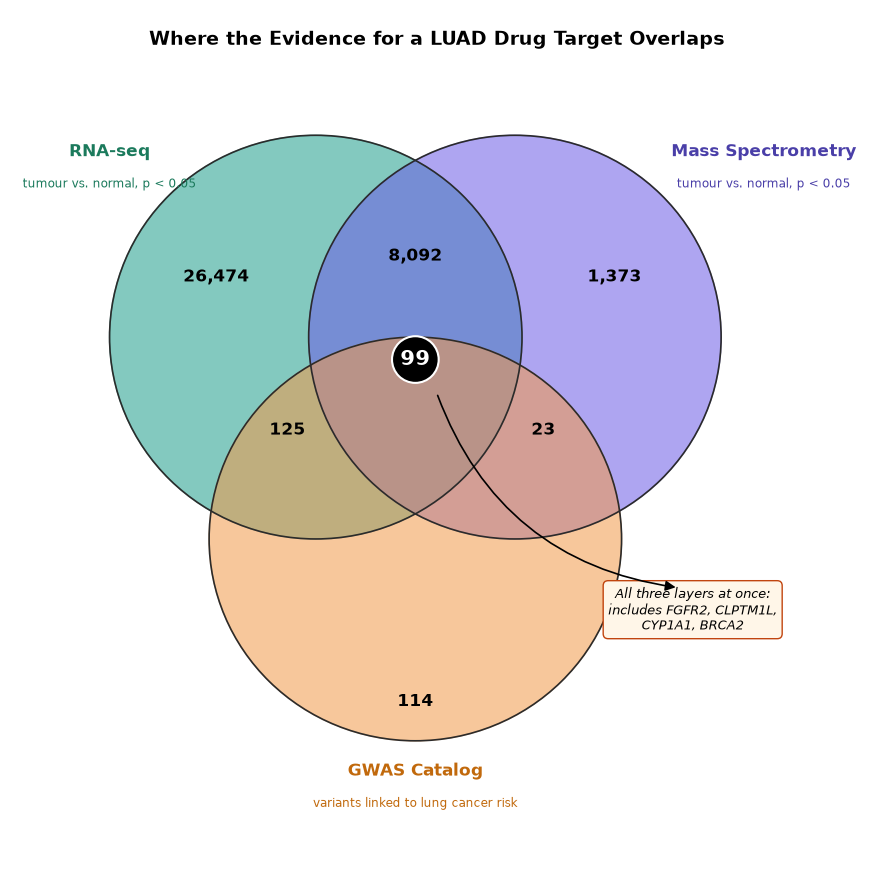

In [5]:
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(9, 9))
ax.set_xlim(0, 12); ax.set_ylim(-1, 11.5); ax.axis('off')

for cx, cy, col in [(4.3, 6.8, "#1E9E8C"), (7.1, 6.8, "#6C5CE7"), (5.7, 3.9, "#F2994A")]:
    ax.add_patch(Circle((cx, cy), 2.9, alpha=0.55, color=col, zorder=1))
    ax.add_patch(Circle((cx, cy), 2.9, fill=False, edgecolor="#2B2B2B", linewidth=1.2, zorder=3))

ax.text(6.0, 11.0, "Where the Evidence for a LUAD Drug Target Overlaps",
        ha='center', fontsize=14, fontweight='bold')
ax.text(1.4, 9.4, "RNA-seq", ha='center', fontsize=12, fontweight='bold', color="#1B7A5C")
ax.text(1.4, 8.95, "tumour vs. normal, p < 0.05", ha='center', fontsize=8.5, color="#1B7A5C")
ax.text(10.6, 9.4, "Mass Spectrometry", ha='center', fontsize=12, fontweight='bold', color="#4A3FA8")
ax.text(10.6, 8.95, "tumour vs. normal, p < 0.05", ha='center', fontsize=8.5, color="#4A3FA8")
ax.text(5.7, 0.5, "GWAS Catalog", ha='center', fontsize=12, fontweight='bold', color="#C1690C")
ax.text(5.7, 0.05, "variants linked to lung cancer risk", ha='center', fontsize=8.5, color="#C1690C")

for x, y, n in [(2.9, 7.6, only_rna), (8.5, 7.6, only_prot), (5.7, 1.5, only_gwas),
                (5.7, 7.9, rna_prot), (3.9, 5.4, rna_gwas), (7.5, 5.4, prot_gwas)]:
    ax.text(x, y, f"{n:,}", ha='center', fontsize=12, fontweight='bold')

ax.text(5.7, 6.4, str(all_three), ha='center', fontsize=15, fontweight='bold', color="white",
        bbox=dict(boxstyle="circle,pad=0.4", facecolor="black", edgecolor="white", linewidth=1.5))
ax.add_patch(FancyArrowPatch((6.0, 6.0), (9.4, 3.2), connectionstyle="arc3,rad=0.3",
             arrowstyle='-|>', mutation_scale=15, linewidth=1.2, color="black", zorder=6))
ax.text(9.6, 2.6, "All three layers at once:\nincludes FGFR2, CLPTM1L,\nCYP1A1, BRCA2",
        ha='center', fontsize=9, fontstyle='italic',
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#FFF6E8", edgecolor="#C1440E"))

plt.tight_layout()
plt.savefig("venn_diagram.png", dpi=220, bbox_inches='tight')
plt.show()